In [2]:
from google.colab import drive
drive.mount("/content/drive")

import numpy as np, pandas as pd, matplotlib.pyplot as plt, os
from scipy.optimize import curve_fit
from scipy.special import voigt_profile

OUT = "/content/drive/MyDrive/cms-dimuon-resonances/results"
os.makedirs(OUT + "/figures", exist_ok=True)

d = np.load(OUT + "/day1_dimuon_hist_full.npz")
regions = {k: (d[f"edges_{k}"], d[f"reg_{k}"]) for k in ["jpsi_psi2s", "upsilon", "z"]}
for k, (e, c) in regions.items():
    print(f"{k:12s} bins: {len(c)}, range {e[0]:.2f}-{e[-1]:.2f} GeV, entries {int(c.sum()):,}")

Mounted at /content/drive
jpsi_psi2s   bins: 140, range 2.60-4.00 GeV, entries 3,816,903
upsilon      bins: 150, range 8.50-11.50 GeV, entries 2,024,739
z            bins: 120, range 60.00-120.00 GeV, entries 3,928,874


In [3]:
PDG = {"J/ψ": 3.096900, "ψ(2S)": 3.686097, "ϒ(1S)": 9.46030, "ϒ(2S)": 10.02326,
       "ϒ(3S)": 10.3551, "Z": 91.1880}     # GeV, checked against PDG pages, October 2026
GAMMA_Z = 2.4955                            # GeV, Z natural width (PDG), fixed input to the Z fit

In [4]:
def gauss(x, mu, sigma, bw):
    """Gaussian, scaled so that the value is expected counts per bin of width bw (per unit yield)."""
    return bw * np.exp(-0.5 * ((x - mu) / sigma) ** 2) / (sigma * np.sqrt(2 * np.pi))

def poly(x, x0, half, b):
    u = (x - x0) / half                       # scaled variable in [-1, 1]
    return sum(bi * u ** i for i, bi in enumerate(b))

def prep(edges, counts, lo, hi):
    c = 0.5 * (edges[1:] + edges[:-1])
    w = np.diff(edges)
    m = (c >= lo) & (c <= hi) & (counts > 0)
    return c[m], counts[m].astype(float), float(w[0])

def run_fit(model, bgf, nsig, c, y, p0, bounds):
    popt, pcov = curve_fit(model, c, y, p0=p0, sigma=np.sqrt(y), absolute_sigma=True,
                           bounds=bounds, max_nfev=20000)
    chi2 = float(np.sum(((y - model(c, *popt)) / np.sqrt(y)) ** 2))
    ndf = len(c) - len(popt)
    lb, ub = map(np.asarray, bounds)
    hit = [i for i in range(len(popt))
           if (np.isfinite(lb[i]) and abs(popt[i] - lb[i]) < 1e-6 * (1 + abs(popt[i])))
           or (np.isfinite(ub[i]) and abs(popt[i] - ub[i]) < 1e-6 * (1 + abs(popt[i])))]
    if hit:
        print("WARNING: parameters stuck at their bounds (indices):", hit)
    return dict(c=c, y=y, model=model, bgf=bgf, nsig=nsig, popt=popt, pcov=pcov, chi2=chi2, ndf=ndf)

def plot_fit(res, title, fname=None, xlabel=r"$m_{\mu\mu}$ [GeV]"):
    c, y, p = res["c"], res["y"], res["popt"]
    xs = np.linspace(c[0], c[-1], 800)
    pull = (y - res["model"](c, *p)) / np.sqrt(y)
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(8, 6.5), sharex=True,
                                 gridspec_kw={"height_ratios": [3, 1], "hspace": 0.05})
    a1.errorbar(c, y, yerr=np.sqrt(y), fmt="k.", ms=3, label="data")
    a1.plot(xs, res["model"](xs, *p), "r-", label="signal + background")
    a1.plot(xs, res["bgf"](xs, *p[res["nsig"]:]), "b--", label="background")
    a1.set(ylabel="Candidates / bin", title=f"{title}   (χ²/ndf = {res['chi2']:.0f}/{res['ndf']})")
    a1.legend()
    a2.axhline(0, color="r")
    a2.plot(c, pull, "k.", ms=3)
    a2.set(xlabel=xlabel, ylabel="pull")
    if fname:
        fig.savefig(f"{OUT}/figures/{fname}", dpi=200, bbox_inches="tight")
    plt.show()

def propagate(f, p, cov):
    """Error on a derived quantity f(p) using numerical derivatives and the fit covariance."""
    p = np.asarray(p, float)
    g = np.zeros_like(p)
    for i in range(len(p)):
        h = 1e-6 * max(abs(p[i]), 1e-3)
        pp, pm = p.copy(), p.copy()
        pp[i] += h; pm[i] -= h
        g[i] = (f(pp) - f(pm)) / (2 * h)
    return f(p), float(np.sqrt(g @ cov @ g))
print("helpers defined")

helpers defined


In [5]:
def fit_jpsi(edges, counts, lo=2.75, hi=3.95):
    c, y, bw = prep(edges, counts, lo, hi)
    x0, half = 0.5 * (lo + hi), 0.5 * (hi - lo)
    def sig(x, NJ, muJ, sJ, f, r, Np, muP, sP):
        return (NJ * (f * gauss(x, muJ, sJ, bw) + (1 - f) * gauss(x, muJ, r * sJ, bw))
                + Np * gauss(x, muP, sP, bw))
    def bgf(x, *b): return poly(x, x0, half, b)
    def model(x, *p): return sig(x, *p[:8]) + bgf(x, *p[8:])
    # starting values from the sidebands (away from the two peaks)
    u = (c - x0) / half
    side = (c < 2.95) | ((c > 3.25) & (c < 3.55)) | (c > 3.82)
    b0 = np.polyfit(u[side], y[side], 3)[::-1]
    bgc = bgf(c, *b0)
    NJ0 = max((y - bgc)[(c > 3.0) & (c < 3.2)].sum(), 1e4)
    Np0 = max((y - bgc)[(c > 3.62) & (c < 3.75)].sum(), 1e3)
    p0 = [NJ0, 3.097, 0.035, 0.7, 2.0, Np0, 3.686, 0.04, *b0]
    lb = [0, 3.05, 0.005, 0, 1.0, 0, 3.65, 0.01] + [-np.inf] * 4
    ub = [np.inf, 3.15, 0.10, 1, 6.0, np.inf, 3.72, 0.15] + [np.inf] * 4
    return run_fit(model, bgf, 8, c, y, p0, (lb, ub))

rj = fit_jpsi(*regions["jpsi_psi2s"])
names_j = ["N_J/ψ", "mu_J/ψ", "sigma1_J/ψ", "f_core", "r (sigma2/sigma1)",
           "N_ψ(2S)", "mu_ψ(2S)", "sigma_ψ(2S)", "b0", "b1", "b2", "b3"]
ej = np.sqrt(np.diag(rj["pcov"]))
for n, v, e in zip(names_j, rj["popt"], ej):
    print(f"{n:18s} {v:14.5f} ± {e:.5f}")
print(f"chi2/ndf = {rj['chi2']:.1f}/{rj['ndf']} = {rj['chi2']/rj['ndf']:.2f}")

N_J/ψ               1617595.93064 ± 1995.93218
mu_J/ψ                    3.09232 ± 0.00003
sigma1_J/ψ                0.02548 ± 0.00010
f_core                    0.54619 ± 0.00473
r (sigma2/sigma1)         2.10281 ± 0.00730
N_ψ(2S)               81179.24537 ± 849.89597
mu_ψ(2S)                  3.68102 ± 0.00033
sigma_ψ(2S)               0.04135 ± 0.00038
b0                    13529.42053 ± 23.28494
b1                    -8547.62827 ± 99.75094
b2                     2620.56344 ± 41.17294
b3                     1910.13867 ± 129.07029
chi2/ndf = 3451.1/108 = 31.95


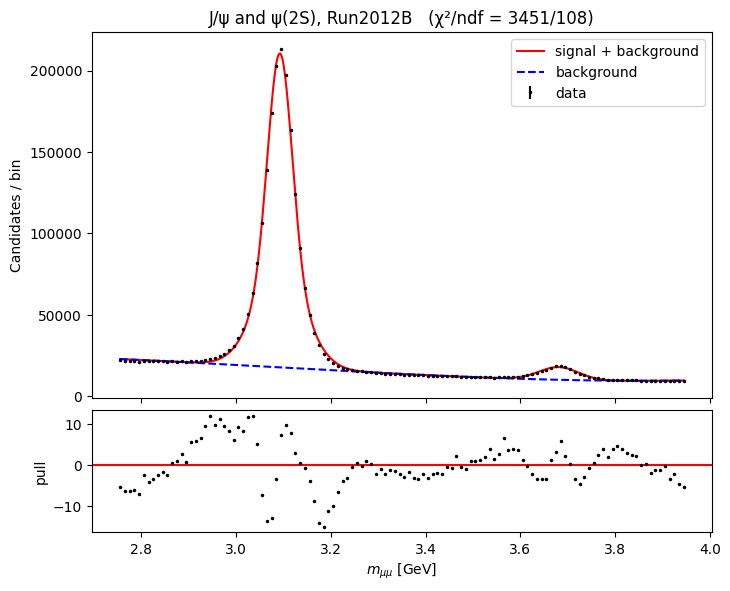

In [6]:
plot_fit(rj, "J/ψ and ψ(2S), Run2012B", "day2_fit_jpsi_psi2s.png")

In [7]:
def fit_upsilon(edges, counts, lo=8.6, hi=11.4):
    c, y, bw = prep(edges, counts, lo, hi)
    x0, half = 0.5 * (lo + hi), 0.5 * (hi - lo)
    def sig(x, N1, N2, N3, m1, m2, m3, s):
        return sum(N * gauss(x, m, s * m, bw) for N, m in ((N1, m1), (N2, m2), (N3, m3)))
    def bgf(x, *b): return poly(x, x0, half, b)
    def model(x, *p): return sig(x, *p[:7]) + bgf(x, *p[7:])
    u = (c - x0) / half
    side = (c < 9.0) | (c > 10.7)
    b0 = np.polyfit(u[side], y[side], 2)[::-1]
    bgc = bgf(c, *b0)
    N0 = [max((y - bgc)[np.abs(c - m) < 2 * 0.011 * m].sum(), 1e3) for m in (9.46, 10.023, 10.355)]
    p0 = [*N0, 9.46, 10.023, 10.355, 0.011, *b0]
    lb = [0, 0, 0, 9.3, 9.9, 10.25, 0.003] + [-np.inf] * 3
    ub = [np.inf] * 3 + [9.6, 10.15, 10.5, 0.03] + [np.inf] * 3
    return run_fit(model, bgf, 7, c, y, p0, (lb, ub))

ru = fit_upsilon(*regions["upsilon"])
names_u = ["N_ϒ(1S)", "N_ϒ(2S)", "N_ϒ(3S)", "m_ϒ(1S)", "m_ϒ(2S)", "m_ϒ(3S)",
           "s_rel", "b0", "b1", "b2"]
eu = np.sqrt(np.diag(ru["pcov"]))
for n, v, e in zip(names_u, ru["popt"], eu):
    print(f"{n:12s} {v:14.5f} ± {e:.5f}")
print(f"chi2/ndf = {ru['chi2']:.1f}/{ru['ndf']} = {ru['chi2']/ru['ndf']:.2f}")

N_ϒ(1S)        118550.61454 ± 898.44979
N_ϒ(2S)         51703.55631 ± 788.74937
N_ϒ(3S)         36444.03864 ± 721.44960
m_ϒ(1S)             9.44634 ± 0.00059
m_ϒ(2S)            10.01094 ± 0.00145
m_ϒ(3S)            10.33515 ± 0.00210
s_rel               0.00972 ± 0.00007
b0              12246.39905 ± 29.87757
b1               -108.46666 ± 17.15980
b2               -382.50921 ± 49.47296
chi2/ndf = 486.4/130 = 3.74


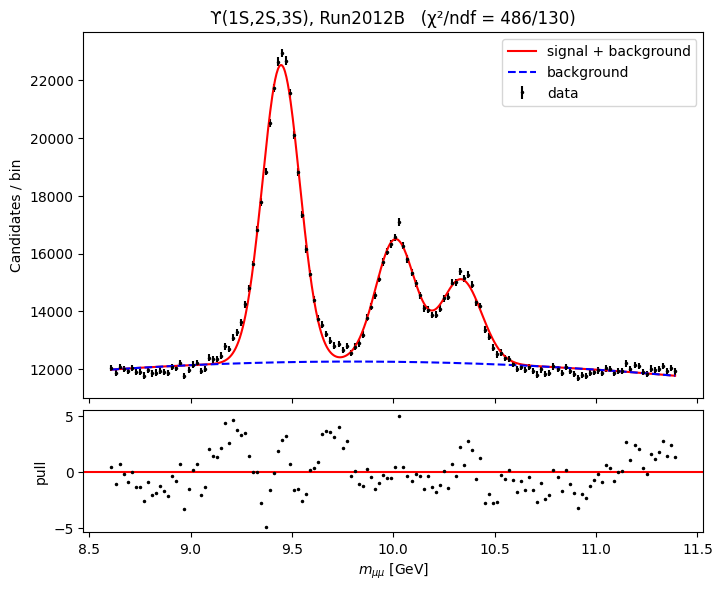

In [8]:
plot_fit(ru, "ϒ(1S,2S,3S), Run2012B", "day2_fit_upsilon.png")

In [9]:
from scipy.special import erf

def cball(x, mu, sigma, alpha, n):
    t = (x - mu) / sigma
    a = abs(alpha)
    A = (n / a) ** n * np.exp(-0.5 * a * a)
    B = n / a - a
    C = n / a / (n - 1) * np.exp(-0.5 * a * a)
    D = np.sqrt(np.pi / 2) * (1 + erf(a / np.sqrt(2)))
    norm = 1.0 / (sigma * (C + D))
    return norm * np.where(t > -a, np.exp(-0.5 * t * t), A * np.maximum(B - t, 1e-12) ** (-n))

def bw_pdf(x, mu, gam):                      # Breit-Wigner, unit area, full width gam
    return (gam / 2 / np.pi) / ((x - mu) ** 2 + (gam / 2) ** 2)

STEP = 0.05
G_GRID = np.arange(40.0, 150.0 + STEP / 2, STEP)        # fine grid, wider than the fit window
K_GRID = np.arange(-15.0, 15.0 + STEP / 2, STEP)        # symmetric kernel grid, odd length
N_CB = 3.0                                              # fixed tail exponent (assumption)

def z_signal(x, N, mu, sigma, alpha, bw):
    k = cball(K_GRID, 0.0, sigma, alpha, N_CB)
    k = k / k.sum()
    conv = np.convolve(bw_pdf(G_GRID, mu, GAMMA_Z), k, mode="same")
    return N * bw * np.interp(x, G_GRID, conv)

def fit_z(edges, counts, lo=75.0, hi=110.0):
    c, y, bw = prep(edges, counts, lo, hi)
    x0, half = 0.5 * (lo + hi), 0.5 * (hi - lo)
    def bgf(x, B, k): return B * np.exp(-k * (x - x0) / half)
    def model(x, *p): return z_signal(x, *p[:4], bw) + bgf(x, *p[4:])
    ylo, yhi = y[:5].mean(), y[-5:].mean()
    B0, k0 = np.sqrt(ylo * yhi), 0.5 * np.log(ylo / yhi)
    p0 = [0.7 * y.sum(), 91.0, 1.2, 1.0, B0, k0]
    lb = [0, 89.0, 0.3, 0.2, 0, -10]
    ub = [np.inf, 93.0, 5.0, 5.0, np.inf, 10]
    return run_fit(model, bgf, 4, c, y, p0, (lb, ub))

rz = fit_z(*regions["z"])
names_z = ["N_Z", "mu_Z", "sigma_Z (CB core)", "alpha_CB", "B", "k"]
ez = np.sqrt(np.diag(rz["pcov"]))
for n, v, e in zip(names_z, rz["popt"], ez):
    print(f"{n:18s} {v:14.5f} ± {e:.5f}")
print(f"chi2/ndf = {rz['chi2']:.1f}/{rz['ndf']} = {rz['chi2']/rz['ndf']:.2f}   (old fit: 217.99)")

N_Z                 2591596.72627 ± 2216.97092
mu_Z                     90.92234 ± 0.00321
sigma_Z (CB core)         1.36876 ± 0.00385
alpha_CB                  1.27313 ± 0.00583
B                      8315.33125 ± 21.81666
k                         0.78675 ± 0.00309
chi2/ndf = 2080.1/64 = 32.50   (old fit: 217.99)


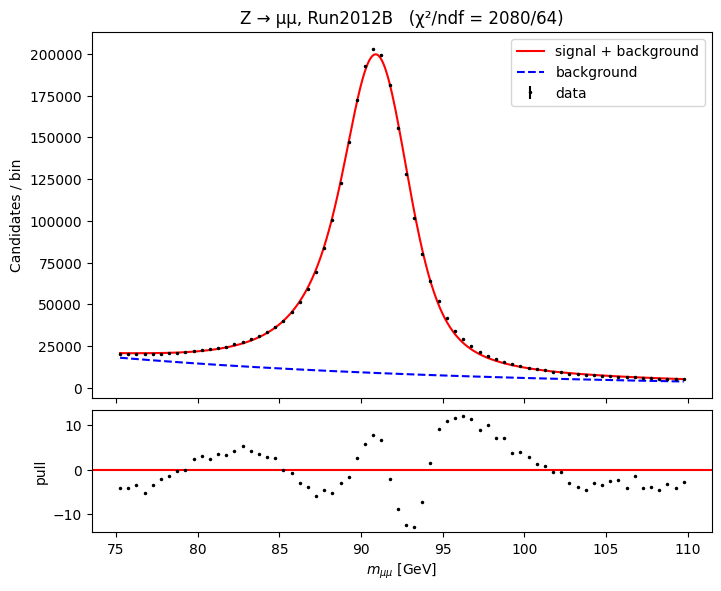

In [10]:
plot_fit(rz, "Z → μμ, Run2012B", "day2_fit_z.png")

In [11]:
def make_table(rj, ru, rz):
    rows = []
    def add(name, m, dm, N, dN, s, ds, res):
        pdg = PDG[name]
        rows.append({"Resonance": name, "m_fit [GeV]": m, "stat [GeV]": dm, "m_PDG [GeV]": pdg,
                     "Δm [MeV]": (m - pdg) * 1e3, "Δm/m [%]": (m - pdg) / pdg * 100,
                     "Yield": N, "Yield err": dN, "σ_res [MeV]": s * 1e3, "σ_res err [MeV]": ds * 1e3,
                     "χ²/ndf": res["chi2"] / res["ndf"]})
    # J/ψ and ψ(2S)
    p, cv = rj["popt"], rj["pcov"]; e = np.sqrt(np.diag(cv))
    s, ds = propagate(lambda q: np.sqrt(q[3] * q[2] ** 2 + (1 - q[3]) * (q[4] * q[2]) ** 2), p, cv)
    add("J/ψ", p[1], e[1], p[0], e[0], s, ds, rj)      # effective sigma of the double Gaussian
    add("ψ(2S)", p[6], e[6], p[5], e[5], p[7], e[7], rj)
    # Upsilons
    p, cv = ru["popt"], ru["pcov"]; e = np.sqrt(np.diag(cv))
    for i, name in enumerate(["ϒ(1S)", "ϒ(2S)", "ϒ(3S)"]):
        s, ds = propagate(lambda q, i=i: q[6] * q[3 + i], p, cv)
        add(name, p[3 + i], e[3 + i], p[i], e[i], s, ds, ru)
    # Z
    p, cv = rz["popt"], rz["pcov"]; e = np.sqrt(np.diag(cv))
    add("Z", p[1], e[1], p[0], e[0], p[2], e[2], rz)
    return pd.DataFrame(rows)

tab = make_table(rj, ru, rz)
pd.set_option("display.width", 200)
print(tab.to_string(index=False, float_format=lambda v: f"{v:.5g}"))

Resonance  m_fit [GeV]  stat [GeV]  m_PDG [GeV]  Δm [MeV]  Δm/m [%]      Yield  Yield err  σ_res [MeV]  σ_res err [MeV]  χ²/ndf
      J/ψ       3.0923  3.3887e-05       3.0969   -4.5756  -0.14775 1.6176e+06     1995.9       40.706         0.098768  31.955
    ψ(2S)        3.681  0.00032803       3.6861   -5.0792  -0.13779      81179      849.9       41.354          0.38239  31.955
    ϒ(1S)       9.4463  0.00058674       9.4603   -13.955  -0.14751 1.1855e+05     898.45       91.784           0.6188  3.7419
    ϒ(2S)       10.011   0.0014492       10.023   -12.322  -0.12293      51704     788.75       97.269          0.65363  3.7419
    ϒ(3S)       10.335   0.0021009       10.355   -19.949  -0.19265      36444     721.45       100.42          0.68015  3.7419
        Z       90.922   0.0032107       91.188   -265.66  -0.29133 2.5916e+06       2217       1368.8            3.851  32.502


In [12]:
tab.to_csv(OUT + "/day2_fit_results.csv", index=False)
print("saved:", os.listdir(OUT))

saved: ['figures', 'day1_dimuon_hist_1M.npz', 'day1_dimuon_hist_full.npz', 'day2_hist_onepair.npz', 'day2_fit_results_onepair.csv', 'day2_fit_results.csv', 'day3_hist_Run2012B.npz', 'day3_binned_fits.csv', 'day3_systematics.csv', 'day3_results_with_uncertainties.csv', 'day3_hist_Run2012C.npz', 'day3_runB_vs_runC.csv']


In [13]:
import importlib.util, subprocess, sys, time
miss = [pip for mod, pip in {"uproot": "uproot", "awkward": "awkward", "fsspec_xrootd": "fsspec-xrootd"}.items()
        if importlib.util.find_spec(mod) is None]
if miss:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q"] + miss)
    print("Installed:", miss, "-> now Runtime > Restart session, then Run all again")

import uproot, awkward as ak
URL_B = "root://eospublic.cern.ch//eos/root-eos/cms_opendata_2012_nanoaod/Run2012B_DoubleMuParked.root"
tree_b = uproot.open(URL_B)["Events"]
branches = ["nMuon", "Muon_pt", "Muon_eta", "Muon_phi", "Muon_mass", "Muon_charge"]
if "Muon_isGlobal" in tree_b.keys():
    branches.append("Muon_isGlobal")
print("Run2012B events:", f"{tree_b.num_entries:,}", "| branches:", branches)

Installed: ['uproot', 'awkward', 'fsspec-xrootd'] -> now Runtime > Restart session, then Run all again
Run2012B events: 29,308,627 | branches: ['nMuon', 'Muon_pt', 'Muon_eta', 'Muon_phi', 'Muon_mass', 'Muon_charge']


In [14]:
tab = make_table(rj, ru, rz)
tab["stat [MeV]"] = tab["stat [GeV]"] * 1e3
tab["scale √(χ²/ndf)"] = np.sqrt(np.maximum(tab["χ²/ndf"], 1.0))
tab["stat scaled [MeV]"] = tab["stat [MeV]"] * tab["scale √(χ²/ndf)"]
print(tab[["Resonance", "Δm [MeV]", "stat [MeV]", "scale √(χ²/ndf)", "stat scaled [MeV]"]]
      .to_string(index=False, float_format=lambda v: f"{v:.4g}"))

Resonance  Δm [MeV]  stat [MeV]  scale √(χ²/ndf)  stat scaled [MeV]
      J/ψ    -4.576     0.03389            5.653             0.1916
    ψ(2S)    -5.079       0.328            5.653              1.854
    ϒ(1S)    -13.96      0.5867            1.934              1.135
    ϒ(2S)    -12.32       1.449            1.934              2.803
    ϒ(3S)    -19.95       2.101            1.934              4.064
        Z    -265.7       3.211            5.701               18.3


In [15]:
def mass_np(pt1, eta1, phi1, m1, pt2, eta2, phi2, m2):
    """Dimuon invariant mass and pair pT from (pt, eta, phi, mass) of each muon."""
    px1 = pt1 * np.cos(phi1); py1 = pt1 * np.sin(phi1); pz1 = pt1 * np.sinh(eta1)
    px2 = pt2 * np.cos(phi2); py2 = pt2 * np.sin(phi2); pz2 = pt2 * np.sinh(eta2)
    E = np.sqrt(px1**2 + py1**2 + pz1**2 + m1**2) + np.sqrt(px2**2 + py2**2 + pz2**2 + m2**2)
    px, py, pz = px1 + px2, py1 + py2, pz1 + pz2
    M = np.sqrt(np.maximum(E**2 - px**2 - py**2 - pz**2, 0))
    return M, np.hypot(px, py)

def pair_arrays(ev):
    """All opposite-sign muon pairs of a chunk (same selection as Days 1-2), as flat arrays."""
    m = ak.zip({k: ev[f"Muon_{k}"] for k in ["pt", "eta", "phi", "mass", "charge"]})
    good = (m.pt > 3.0) & (np.abs(m.eta) < 2.4)
    if "Muon_isGlobal" in ev.fields:
        good = good & ev["Muon_isGlobal"]
    pr = ak.combinations(m[good], 2, fields=["mu1", "mu2"])
    pr = pr[(pr.mu1.charge * pr.mu2.charge) < 0]
    g = lambda a, k: ak.to_numpy(ak.flatten(pr[a][k]))
    pt1, eta1, phi1, ms1 = g("mu1", "pt"), g("mu1", "eta"), g("mu1", "phi"), g("mu1", "mass")
    pt2, eta2, phi2, ms2 = g("mu2", "pt"), g("mu2", "eta"), g("mu2", "phi"), g("mu2", "mass")
    M, ptp = mass_np(pt1, eta1, phi1, ms1, pt2, eta2, phi2, ms2)
    return dict(M=M, ptp=ptp, etamax=np.maximum(np.abs(eta1), np.abs(eta2)),
                minpt=np.minimum(pt1, pt2), pt1=pt1, pt2=pt2, eta1=eta1, eta2=eta2)

ETA_EDGES = np.array([0.0, 0.9, 1.2, 2.5])      # categories of the larger |eta| of the two muons
TAGS = ["nom", "minpt5", "pt0", "pt1", "pt2", "pt3", "eta0", "eta1", "eta2"]

def run_pass(tree, branches, pt_edges, n_stop=None, step=200_000):
    H = {(r, t): np.zeros(len(regions[r][1])) for r in regions for t in TAGS}
    n_done, t0 = 0, time.time()
    for ev in tree.iterate(branches, step_size=step, entry_stop=n_stop):
        a = pair_arrays(ev)
        for r in regions:
            edges, pe = regions[r][0], pt_edges[r]
            masks = {"nom": np.ones(a["M"].shape, bool), "minpt5": a["minpt"] > 5.0}
            for i in range(4):
                masks[f"pt{i}"] = (a["ptp"] >= pe[i]) & (a["ptp"] < pe[i + 1])
            for i in range(3):
                masks[f"eta{i}"] = (a["etamax"] >= ETA_EDGES[i]) & (a["etamax"] < ETA_EDGES[i + 1])
            for t, mk in masks.items():
                H[(r, t)] += np.histogram(a["M"][mk], bins=edges)[0]
        n_done += len(ev["nMuon"])
        if (n_done // step) % 10 == 0:
            print(f"processed {n_done:,} events ({time.time()-t0:.0f}s)")
    print(f"done: {n_done:,} events in {time.time()-t0:.0f}s")
    return H, n_done
print("functions defined")

functions defined


In [16]:
win = {"jpsi_psi2s": (3.0, 3.2), "upsilon": (9.2, 9.7), "z": (85.0, 97.0)}
samples = {r: [] for r in win}
for ev in tree_b.iterate(branches, step_size=200_000, entry_stop=1_000_000):
    a = pair_arrays(ev)
    for r, (lo, hi) in win.items():
        samples[r].append(a["ptp"][(a["M"] > lo) & (a["M"] < hi)])
PT_EDGES = {}
for r in win:
    v = np.concatenate(samples[r])
    q = np.round(np.quantile(v, [0.25, 0.5, 0.75]) * 2) / 2      # rounded to 0.5 GeV
    PT_EDGES[r] = np.array([0.0, *q, 10000.0])
    print(f"{r:11s} pairs in window: {len(v):,}   pair-pT edges: {PT_EDGES[r][:4]}")

jpsi_psi2s  pairs in window: 65,729   pair-pT edges: [ 0.  20.5 25.5 31.5]
upsilon     pairs in window: 14,402   pair-pT edges: [ 0.   8.5 19.  27. ]
z           pairs in window: 79,439   pair-pT edges: [ 0.   6.  12.5 26.5]


In [17]:
H_B, n_B = run_pass(tree_b, branches, PT_EDGES)
np.savez(OUT + "/day3_hist_Run2012B.npz", n_events=n_B,
         **{f"{r}__{t}": v for (r, t), v in H_B.items()},
         **{f"ptedges_{r}": PT_EDGES[r] for r in PT_EDGES})
print("saved day3_hist_Run2012B.npz")

processed 2,000,000 events (16s)
processed 4,000,000 events (27s)
processed 6,000,000 events (36s)
processed 8,000,000 events (44s)
processed 10,000,000 events (53s)
processed 12,000,000 events (62s)
processed 14,000,000 events (70s)
processed 16,000,000 events (78s)
processed 18,000,000 events (89s)
processed 20,000,000 events (99s)
processed 22,000,000 events (109s)
processed 24,000,000 events (117s)
processed 26,000,000 events (128s)
processed 28,000,000 events (139s)
done: 29,308,627 events in 144s
saved day3_hist_Run2012B.npz


In [18]:
def fit_jpsi_bin(edges, counts, lo=2.8, hi=3.4):
    c, y, bw = prep(edges, counts, lo, hi)
    x0, half = 0.5 * (lo + hi), 0.5 * (hi - lo)
    def sig(x, N, mu, s, f, r): return N * (f * gauss(x, mu, s, bw) + (1 - f) * gauss(x, mu, r * s, bw))
    def bgf(x, *b): return poly(x, x0, half, b)
    def model(x, *p): return sig(x, *p[:5]) + bgf(x, *p[5:])
    u = (c - x0) / half
    side = (c < 2.95) | (c > 3.25)
    b0 = np.polyfit(u[side], y[side], 2)[::-1]
    N0 = max((y - bgf(c, *b0))[(c > 3.0) & (c < 3.2)].sum(), 1e3)
    p0 = [N0, 3.093, 0.025, 0.55, 2.1, *b0]
    lb = [0, 3.05, 0.005, 0, 1.0] + [-np.inf] * 3
    ub = [np.inf, 3.15, 0.10, 1, 6.0] + [np.inf] * 3
    return run_fit(model, bgf, 5, c, y, p0, (lb, ub))

def fit_y1s_bin(edges, counts, lo=8.8, hi=9.75):
    c, y, bw = prep(edges, counts, lo, hi)
    x0, half = 0.5 * (lo + hi), 0.5 * (hi - lo)
    def sig(x, N, mu, s): return N * gauss(x, mu, s, bw)
    def bgf(x, *b): return poly(x, x0, half, b)
    def model(x, *p): return sig(x, *p[:3]) + bgf(x, *p[3:])
    u = (c - x0) / half
    side = (c < 9.1) | (c > 9.65)
    b0 = np.polyfit(u[side], y[side], 1)[::-1]
    N0 = max((y - bgf(c, *b0))[(c > 9.3) & (c < 9.6)].sum(), 1e3)
    p0 = [N0, 9.45, 0.09, *b0]
    lb = [0, 9.3, 0.02] + [-np.inf] * 2
    ub = [np.inf, 9.6, 0.25] + [np.inf] * 2
    return run_fit(model, bgf, 3, c, y, p0, (lb, ub))

def fit_tag(r, counts):
    edges = regions[r][0]
    if r == "jpsi_psi2s": return fit_jpsi_bin(edges, counts)
    if r == "upsilon":    return fit_y1s_bin(edges, counts)
    return fit_z(edges, counts)

def summarize(r, res):
    p, cv = res["popt"], res["pcov"]; e = np.sqrt(np.diag(cv))
    if r == "jpsi_psi2s":    # effective sigma of the double Gaussian
        s, ds = propagate(lambda q: np.sqrt(q[3] * q[2]**2 + (1 - q[3]) * (q[4] * q[2])**2), p, cv)
    else:
        s, ds = p[2], e[2]
    return dict(m=p[1], m_err_MeV=e[1] * 1e3, sigma_MeV=s * 1e3, sigma_err_MeV=ds * 1e3,
                N=p[0], chi2ndf=res["chi2"] / res["ndf"])

def tag_label(r, t):
    if t == "nom": return "inclusive"
    if t == "minpt5": return "min muon pT > 5"
    e = PT_EDGES[r]
    if t.startswith("pt"):
        i = int(t[2:])
        return f"pair pT < {e[1]:g}" if i == 0 else (f"pair pT > {e[3]:g}" if i == 3 else f"pair pT {e[i]:g}-{e[i+1]:g}")
    return ["max|η| < 0.9", "0.9 < max|η| < 1.2", "1.2 < max|η| < 2.4"][int(t[3:])]
print("ok")

ok


In [19]:
rows = []
for r in regions:
    for t in TAGS:
        counts = H_B[(r, t)]
        if counts.sum() < 5000:
            print(f"skipped {r} {t}: only {int(counts.sum())} entries"); continue
        try:
            s = summarize(r, fit_tag(r, counts))
        except Exception as ex:
            print(f"FIT FAILED {r} {t}: {ex}"); continue
        rows.append(dict(region=r, tag=t, label=tag_label(r, t), entries=int(counts.sum()), **s))
df3 = pd.DataFrame(rows)
ref = df3[df3.tag == "nom"].set_index("region")["m"]
df3["Δm vs inclusive [MeV]"] = (df3["m"] - df3["region"].map(ref)) * 1e3
pd.set_option("display.width", 220)
print(df3[["region", "label", "entries", "m", "m_err_MeV", "Δm vs inclusive [MeV]",
           "sigma_MeV", "sigma_err_MeV", "chi2ndf"]].to_string(index=False, float_format=lambda v: f"{v:.5g}"))
df3.to_csv(OUT + "/day3_binned_fits.csv", index=False)

    region              label  entries      m  m_err_MeV  Δm vs inclusive [MeV]  sigma_MeV  sigma_err_MeV  chi2ndf
jpsi_psi2s          inclusive  3816903 3.0924   0.034011                      0     39.183        0.10981   47.399
jpsi_psi2s    min muon pT > 5  2896203 3.0924   0.034082               0.012666     38.961         0.1021   50.409
jpsi_psi2s     pair pT < 20.5  1310595 3.0922   0.082186               -0.19204     39.286        0.29726   10.233
jpsi_psi2s  pair pT 20.5-25.5   762800  3.092   0.063821               -0.33815     38.374        0.18918   17.843
jpsi_psi2s  pair pT 25.5-31.5   810015 3.0925   0.060837                0.10216     38.749        0.18153    15.12
jpsi_psi2s     pair pT > 31.5   933492 3.0927   0.067927                 0.3252      40.56        0.21232   11.096
jpsi_psi2s       max|η| < 0.9  1475714 3.0933   0.036583                0.96814     29.867        0.11703   33.287
jpsi_psi2s 0.9 < max|η| < 1.2   485181 3.0933   0.085297                0.89181 

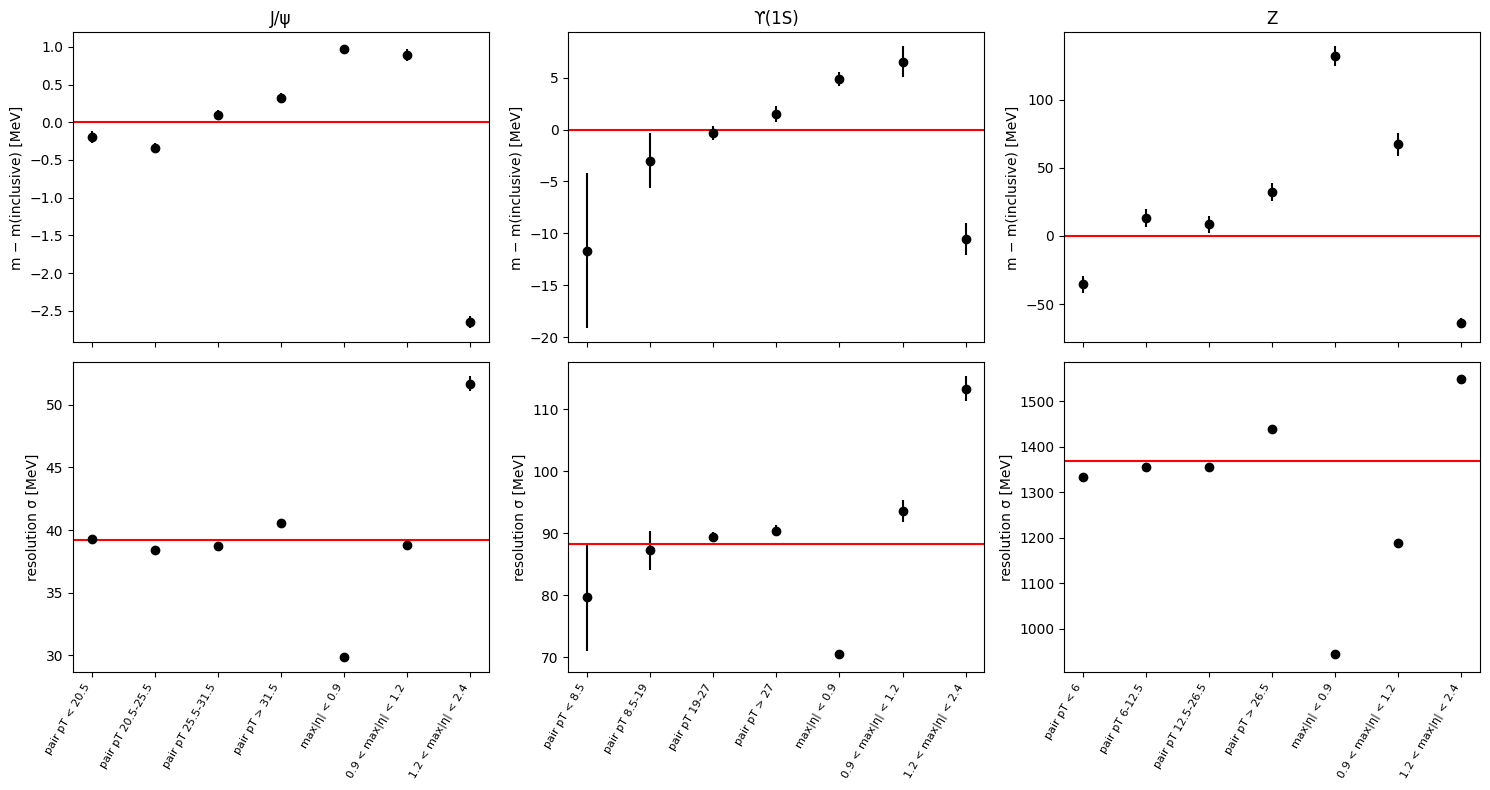

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for j, (r, title) in enumerate([("jpsi_psi2s", "J/ψ"), ("upsilon", "ϒ(1S)"), ("z", "Z")]):
    d = df3[(df3.region == r) & (df3.tag.isin(["pt0", "pt1", "pt2", "pt3", "eta0", "eta1", "eta2"]))].reset_index(drop=True)
    inc = df3[(df3.region == r) & (df3.tag == "nom")].iloc[0]
    x = np.arange(len(d))
    axes[0, j].errorbar(x, d["Δm vs inclusive [MeV]"], yerr=d["m_err_MeV"], fmt="ko")
    axes[0, j].axhline(0, color="r"); axes[0, j].set_title(title)
    axes[0, j].set_ylabel("m − m(inclusive) [MeV]"); axes[0, j].set_xticks(x); axes[0, j].set_xticklabels([])
    axes[1, j].errorbar(x, d["sigma_MeV"], yerr=d["sigma_err_MeV"], fmt="ko")
    axes[1, j].axhline(inc["sigma_MeV"], color="r")
    axes[1, j].set_ylabel("resolution σ [MeV]"); axes[1, j].set_xticks(x)
    axes[1, j].set_xticklabels(d["label"], rotation=60, ha="right", fontsize=8)
plt.tight_layout()
plt.savefig(OUT + "/figures/day3_pt_eta_dependence.png", dpi=200)
plt.show()

In [21]:
def refit_all(h):
    return (fit_jpsi(regions["jpsi_psi2s"][0], h["jpsi_psi2s"]),
            fit_upsilon(regions["upsilon"][0], h["upsilon"]),
            fit_z(regions["z"][0], h["z"]))

def masses_of(rj_, ru_, rz_):
    return {"J/ψ": rj_["popt"][1], "ψ(2S)": rj_["popt"][6], "ϒ(1S)": ru_["popt"][3],
            "ϒ(2S)": ru_["popt"][4], "ϒ(3S)": ru_["popt"][5], "Z": rz_["popt"][1]}

nom = masses_of(rj, ru, rz)
syst = {}
def add_syst(src, new):
    syst.setdefault(src, {})
    for n, v in new.items():
        syst[src][n] = max(abs(v - nom[n]) * 1e3, syst[src].get(n, 0.0))   # keep the largest shift, in MeV

def fit_jpsi_cb(edges, counts, start, lo=2.75, hi=3.95, n_fixed=3.0):
    c, y, bw = prep(edges, counts, lo, hi)
    x0, half = 0.5 * (lo + hi), 0.5 * (hi - lo)
    def sig(x, NJ, muJ, sJ, f, r, alpha, Np, muP, sP):
        return (NJ * f * bw * cball(x, muJ, sJ, alpha, n_fixed) + NJ * (1 - f) * gauss(x, muJ, r * sJ, bw)
                + Np * gauss(x, muP, sP, bw))
    def bgf(x, *b): return poly(x, x0, half, b)
    def model(x, *p): return sig(x, *p[:9]) + bgf(x, *p[9:])
    p0 = [start[0], start[1], start[2], start[3], start[4], 1.5, start[5], start[6], start[7], *start[8:12]]
    lb = [0, 3.05, 0.005, 0, 1.0, 0.2, 0, 3.65, 0.01] + [-np.inf] * 4
    ub = [np.inf, 3.15, 0.10, 1, 6.0, 5.0, np.inf, 3.72, 0.15] + [np.inf] * 4
    return run_fit(model, bgf, 9, c, y, p0, (lb, ub))

def fit_upsilon_deg(edges, counts, lo=8.6, hi=11.4, deg=3):
    c, y, bw = prep(edges, counts, lo, hi)
    x0, half = 0.5 * (lo + hi), 0.5 * (hi - lo)
    def sig(x, N1, N2, N3, m1, m2, m3, s):
        return sum(N * gauss(x, m, s * m, bw) for N, m in ((N1, m1), (N2, m2), (N3, m3)))
    def bgf(x, *b): return poly(x, x0, half, b)
    def model(x, *p): return sig(x, *p[:7]) + bgf(x, *p[7:])
    u = (c - x0) / half
    side = (c < 9.0) | (c > 10.7)
    b0 = np.polyfit(u[side], y[side], deg)[::-1]
    N0 = [max((y - bgf(c, *b0))[np.abs(c - m) < 2 * 0.011 * m].sum(), 1e3) for m in (9.46, 10.023, 10.355)]
    p0 = [*N0, 9.46, 10.023, 10.355, 0.011, *b0]
    lb = [0, 0, 0, 9.3, 9.9, 10.25, 0.003] + [-np.inf] * (deg + 1)
    ub = [np.inf] * 3 + [9.6, 10.15, 10.5, 0.03] + [np.inf] * (deg + 1)
    return run_fit(model, bgf, 7, c, y, p0, (lb, ub))
print("nominal masses [GeV]:", {k: round(v, 5) for k, v in nom.items()})

nominal masses [GeV]: {'J/ψ': np.float64(3.09232), 'ψ(2S)': np.float64(3.68102), 'ϒ(1S)': np.float64(9.44634), 'ϒ(2S)': np.float64(10.01094), 'ϒ(3S)': np.float64(10.33515), 'Z': np.float64(90.92234)}


In [22]:
# (a) fit window
for lo, hi in [(2.8, 3.9), (2.85, 3.85), (2.7, 4.0)]:
    r_ = fit_jpsi(*regions["jpsi_psi2s"], lo=lo, hi=hi)
    add_syst("fit window", {"J/ψ": r_["popt"][1], "ψ(2S)": r_["popt"][6]})
for lo, hi in [(8.7, 11.3), (8.8, 11.2), (8.5, 11.5)]:
    r_ = fit_upsilon(*regions["upsilon"], lo=lo, hi=hi)
    add_syst("fit window", {"ϒ(1S)": r_["popt"][3], "ϒ(2S)": r_["popt"][4], "ϒ(3S)": r_["popt"][5]})
for lo, hi in [(70, 110), (80, 105), (80, 100), (70, 115)]:
    r_ = fit_z(*regions["z"], lo=lo, hi=hi)
    add_syst("fit window", {"Z": r_["popt"][1]})

# (b) signal / background model
r_ = fit_jpsi_cb(*regions["jpsi_psi2s"], start=rj["popt"])
add_syst("signal/background model", {"J/ψ": r_["popt"][1], "ψ(2S)": r_["popt"][7]})
r_ = fit_upsilon_deg(*regions["upsilon"], deg=3)
add_syst("signal/background model", {"ϒ(1S)": r_["popt"][3], "ϒ(2S)": r_["popt"][4], "ϒ(3S)": r_["popt"][5]})
for n_alt in (2.0, 5.0):                  # Crystal Ball tail exponent for the Z (nominal 3)
    N_CB = n_alt
    try:
        r_ = fit_z(*regions["z"])
        add_syst("signal/background model", {"Z": r_["popt"][1]})
    finally:
        N_CB = 3.0

# (c) one opposite-sign pair per event (saved on Day 2)
op_path = OUT + "/day2_hist_onepair.npz"
if os.path.exists(op_path):
    op = np.load(op_path)
    add_syst("one pair per event", masses_of(*refit_all({k: op[f"reg_{k}"] for k in regions})))
else:
    print("day2_hist_onepair.npz not found: skipping the one-pair variation")

# (d) harder muon pT cut: both muons > 5 GeV (from the Part 2 pass)
add_syst("min muon pT > 5 GeV", masses_of(*refit_all({r: H_B[(r, "minpt5")] for r in regions})))

src_cols = list(syst.keys())
sdf = pd.DataFrame({s: pd.Series(syst[s]) for s in src_cols}).reindex(list(nom))
sdf["total syst [MeV]"] = np.sqrt((sdf[src_cols].fillna(0.0) ** 2).sum(axis=1))
print(sdf.to_string(float_format=lambda v: f"{v:.3g}"))
sdf.to_csv(OUT + "/day3_systematics.csv")

       fit window  signal/background model  one pair per event  min muon pT > 5 GeV  total syst [MeV]
J/ψ        0.0985                    0.922              0.0738              0.00666              0.93
ψ(2S)       0.587                    0.245               0.793                0.338              1.07
ϒ(1S)       0.183                    0.194                1.09                0.644               1.3
ϒ(2S)        1.56                     3.85               0.922                0.559              4.29
ϒ(3S)       0.321                      2.7                1.78                 1.87              3.75
Z            23.2                     26.6                5.36                0.788              35.7


In [23]:
fin = tab.set_index("Resonance")
res_tab = pd.DataFrame({"Δm (fit − PDG) [MeV]": fin["Δm [MeV]"],
                        "stat, scaled [MeV]": fin["stat scaled [MeV]"],
                        "syst (evaluated) [MeV]": sdf["total syst [MeV]"]})
res_tab["total [MeV]"] = np.sqrt(res_tab["stat, scaled [MeV]"]**2 + res_tab["syst (evaluated) [MeV]"]**2)
res_tab["|Δm| / total"] = res_tab["Δm (fit − PDG) [MeV]"].abs() / res_tab["total [MeV]"]
print(res_tab.to_string(float_format=lambda v: f"{v:.3g}"))
res_tab.to_csv(OUT + "/day3_results_with_uncertainties.csv")

       Δm (fit − PDG) [MeV]  stat, scaled [MeV]  syst (evaluated) [MeV]  total [MeV]  |Δm| / total
J/ψ                   -4.58               0.192                    0.93         0.95          4.82
ψ(2S)                 -5.08                1.85                    1.07         2.14          2.37
ϒ(1S)                   -14                1.13                     1.3         1.72           8.1
ϒ(2S)                 -12.3                 2.8                    4.29         5.12           2.4
ϒ(3S)                 -19.9                4.06                    3.75         5.53          3.61
Z                      -266                18.3                    35.7         40.2          6.62


In [31]:
def check(name, ok, detail=""):
    print(("PASS  " if ok else "FAIL  ") + name + (f"   [{detail}]" if detail else ""))
    return ok

# 1. mass function: two back-to-back muons, pT 45.59 GeV, eta 0 -> Z-like mass
M1, _ = mass_np(np.array([45.59]), np.array([0.0]), np.array([0.0]), np.array([0.10566]),
                np.array([45.59]), np.array([0.0]), np.array([np.pi]), np.array([0.10566]))
check("back-to-back muons give about 91.18 GeV", abs(M1[0] - 91.18) < 0.01, f"{M1[0]:.4f}")

# 2. two muons with identical momentum -> mass = 2 * muon mass
M2, _ = mass_np(np.array([10.0]), np.array([0.5]), np.array([1.0]), np.array([0.10566]),
                np.array([10.0]), np.array([0.5]), np.array([1.0]), np.array([0.10566]))
check("identical momenta give 2 m_mu", abs(M2[0] - 2 * 0.10566) < 1e-3, f"{M2[0]:.5f}")

# 3. this pass reproduces the Day 1 histograms (same selection)
for r in regions:
    d1 = regions[r][1]; d3 = H_B[(r, "nom")]
    check(f"Day 3 nominal histogram = Day 1 histogram ({r})",
          np.abs(d3 - d1).sum() <= 1e-6 * d1.sum(), f"sum|diff| = {np.abs(d3 - d1).sum():.0f} of {d1.sum():.0f}")

# 4. pT bins cover the nominal sample (a handful of pairs have pair pT above the last edge),
#    and the eta categories partition it exactly
for r in regions:
    total = H_B[(r, "nom")].sum()
    lost = total - sum(H_B[(r, f"pt{i}")] for i in range(4)).sum()
    check(f"pT bins cover the nominal sample to < 0.01% ({r})",
          0 <= lost <= 1e-4 * total, f"{int(lost)} of {int(total)} pairs outside the bins")
    check(f"eta categories sum to nominal ({r})",
          np.array_equal(sum(H_B[(r, f"eta{i}")] for i in range(3)), H_B[(r, "nom")]))

# 5. fitted masses within 1% of PDG, yields positive
for n, v in nom.items():
    check(f"{n} mass within 1% of PDG", abs(v - PDG[n]) / PDG[n] < 0.01, f"{v:.4f} vs {PDG[n]:.4f}")
_ = check("all fitted yields positive",
          min(rj["popt"][0], rj["popt"][5], *ru["popt"][:3], rz["popt"][0]) > 0)

PASS  back-to-back muons give about 91.18 GeV   [91.1802]
PASS  identical momenta give 2 m_mu   [0.21132]
PASS  Day 3 nominal histogram = Day 1 histogram (jpsi_psi2s)   [sum|diff| = 0 of 3816903]
PASS  Day 3 nominal histogram = Day 1 histogram (upsilon)   [sum|diff| = 0 of 2024739]
PASS  Day 3 nominal histogram = Day 1 histogram (z)   [sum|diff| = 0 of 3928874]
PASS  pT bins cover the nominal sample to < 0.01% (jpsi_psi2s)   [1 of 3816903 pairs outside the bins]
PASS  eta categories sum to nominal (jpsi_psi2s)
PASS  pT bins cover the nominal sample to < 0.01% (upsilon)   [9 of 2024739 pairs outside the bins]
PASS  eta categories sum to nominal (upsilon)
PASS  pT bins cover the nominal sample to < 0.01% (z)   [120 of 3928874 pairs outside the bins]
PASS  eta categories sum to nominal (z)
PASS  J/ψ mass within 1% of PDG   [3.0923 vs 3.0969]
PASS  ψ(2S) mass within 1% of PDG   [3.6810 vs 3.6861]
PASS  ϒ(1S) mass within 1% of PDG   [9.4463 vs 9.4603]
PASS  ϒ(2S) mass within 1% of PDG   [10

In [25]:
def toy_test(fitter, res, edges, counts, lo, hi, idx, nt=100, seed=1):
    rng = np.random.default_rng(seed)
    cc = 0.5 * (edges[1:] + edges[:-1]); inside = (cc >= lo) & (cc <= hi)
    mu_true = res["popt"][idx]
    mean_exp = np.clip(res["model"](cc[inside], *res["popt"]), 0, None)
    pulls = []
    for _ in range(nt):
        ct = counts.astype(float).copy()
        ct[inside] = rng.poisson(mean_exp)
        try:
            r_ = fitter(edges, ct, lo=lo, hi=hi)
        except Exception:
            continue
        pulls.append((r_["popt"][idx] - mu_true) / np.sqrt(r_["pcov"][idx, idx]))
    p = np.array(pulls); n = len(p)
    ok = n >= 0.8 * nt and abs(p.mean()) < 3 / np.sqrt(n) and abs(p.std() - 1) < 3 / np.sqrt(2 * n)
    return ok, n, p.mean(), p.std()

t0 = time.time()
for name, fitter, res, r, lo, hi, idx, nt in [
        ("J/ψ mass", fit_jpsi,    rj, "jpsi_psi2s", 2.75, 3.95, 1, 100),
        ("ϒ(1S) mass", fit_upsilon, ru, "upsilon",    8.6, 11.4, 3, 100),
        ("Z mass",   fit_z,       rz, "z",          75.0, 110.0, 1, 50)]:
    ok, n, mean, std = toy_test(fitter, res, *regions[r], lo, hi, idx, nt)
    check(f"toy closure, {name}", ok, f"{n} toys, pull mean {mean:+.2f}, pull width {std:.2f}")
print(f"{time.time()-t0:.0f}s")

PASS  toy closure, J/ψ mass   [100 toys, pull mean +0.01, pull width 0.93]
PASS  toy closure, ϒ(1S) mass   [100 toys, pull mean -0.08, pull width 1.01]
PASS  toy closure, Z mass   [50 toys, pull mean +0.03, pull width 1.06]
5s


In [26]:
URL_C = "root://eospublic.cern.ch//eos/root-eos/cms_opendata_2012_nanoaod/Run2012C_DoubleMuParked.root"
tree_c = uproot.open(URL_C)["Events"]
assert all(b in tree_c.keys() for b in branches), "a branch is missing in Run2012C"
N_C = min(tree_c.num_entries, 30_000_000)           # cap the running time
print(f"Run2012C has {tree_c.num_entries:,} events; processing {N_C:,}")
H_C, n_C = run_pass(tree_c, branches, PT_EDGES, n_stop=N_C)
np.savez(OUT + "/day3_hist_Run2012C.npz", n_events=n_C,
         **{f"{r}__{t}": v for (r, t), v in H_C.items()})

mC = masses_of(*refit_all({r: H_C[(r, "nom")] for r in regions}))
cmpC = pd.DataFrame({"Run2012B [GeV]": nom, "Run2012C [GeV]": mC})
cmpC["C − B [MeV]"] = (cmpC["Run2012C [GeV]"] - cmpC["Run2012B [GeV]"]) * 1e3
cmpC["syst (evaluated) [MeV]"] = sdf["total syst [MeV]"]
print(cmpC.to_string(float_format=lambda v: f"{v:.5g}"))
cmpC.to_csv(OUT + "/day3_runB_vs_runC.csv")

Run2012C has 36,820,243 events; processing 30,000,000
processed 2,000,000 events (7s)
processed 4,000,000 events (15s)
processed 6,000,000 events (23s)
processed 8,000,000 events (31s)
processed 10,000,000 events (40s)
processed 12,000,000 events (49s)
processed 14,000,000 events (59s)
processed 16,000,000 events (68s)
processed 18,000,000 events (78s)
processed 20,000,000 events (87s)
processed 22,000,000 events (99s)
processed 24,000,000 events (108s)
processed 26,000,000 events (117s)
processed 28,000,000 events (125s)
processed 30,000,000 events (134s)
done: 30,000,000 events in 134s
       Run2012B [GeV]  Run2012C [GeV]  C − B [MeV]  syst (evaluated) [MeV]
J/ψ            3.0923          3.0924       0.1021                 0.93027
ψ(2S)           3.681          3.6809     -0.11431                   1.071
ϒ(1S)          9.4463          9.4472      0.89452                  1.2968
ϒ(2S)          10.011          10.011     0.010637                  4.2903
ϒ(3S)          10.335         

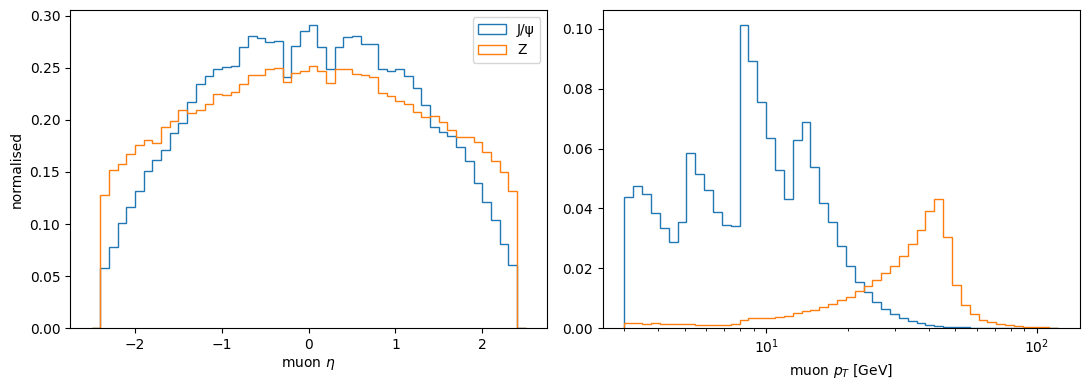

In [27]:
accept = {"J/ψ": dict(eta=[], pt=[]), "Z": dict(eta=[], pt=[])}
winA = {"J/ψ": (3.0, 3.2), "Z": (85.0, 97.0)}
for ev in tree_b.iterate(branches, step_size=200_000, entry_stop=3_000_000):
    a = pair_arrays(ev)
    for n, (lo, hi) in winA.items():
        s = (a["M"] > lo) & (a["M"] < hi)
        accept[n]["eta"].append(np.concatenate([a["eta1"][s], a["eta2"][s]]))
        accept[n]["pt"].append(np.concatenate([a["pt1"][s], a["pt2"][s]]))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for n in accept:
    ax[0].hist(np.concatenate(accept[n]["eta"]), bins=np.linspace(-2.5, 2.5, 51), histtype="step", density=True, label=n)
    ax[1].hist(np.concatenate(accept[n]["pt"]), bins=np.logspace(np.log10(3), np.log10(120), 50), histtype="step", density=True, label=n)
ax[0].set(xlabel=r"muon $\eta$", ylabel="normalised"); ax[1].set(xlabel=r"muon $p_T$ [GeV]", xscale="log")
ax[0].legend(); plt.tight_layout()
plt.savefig(OUT + "/figures/day3_acceptance_view.png", dpi=200); plt.show()

In [28]:
expected = ["day3_hist_Run2012B.npz", "day3_binned_fits.csv", "day3_systematics.csv",
            "day3_results_with_uncertainties.csv", "day3_hist_Run2012C.npz", "day3_runB_vs_runC.csv"]
have = os.listdir(OUT)
for f in expected:
    print(("OK       " if f in have else "MISSING  ") + f)
print("figures:", sorted(os.listdir(OUT + "/figures")))

OK       day3_hist_Run2012B.npz
OK       day3_binned_fits.csv
OK       day3_systematics.csv
OK       day3_results_with_uncertainties.csv
OK       day3_hist_Run2012C.npz
OK       day3_runB_vs_runC.csv
figures: ['day1_dimuon_spectrum.png', 'day1_dimuon_spectrum_first_look.png', 'day1_dimuon_spectrum_full.png', 'day2_fit_jpsi_psi2s.png', 'day2_fit_jpsi_psi2s_cb.png', 'day2_fit_upsilon.png', 'day2_fit_z.png', 'day3_acceptance_view.png', 'day3_pt_eta_dependence.png']


In [29]:
saved = np.load(OUT + "/day3_hist_Run2012B.npz")
for r in regions:
    nom_h = H_B[(r, "nom")]
    s = sum(H_B[(r, f"pt{i}")] for i in range(4))
    print(f"{r}: nominal {int(nom_h.sum()):,} | sum of pT bins {int(s.sum()):,} | "
          f"pairs in no pT bin {int((nom_h - s).clip(0).sum()):,} | extra {int((s - nom_h).clip(0).sum()):,}")
    print("   edges in memory:", PT_EDGES[r], "| edges saved with the pass:", saved[f"ptedges_{r}"])
    print("   entries per pT bin:", [int(H_B[(r, f'pt{i}')].sum()) for i in range(4)])

jpsi_psi2s: nominal 3,816,903 | sum of pT bins 3,816,902 | pairs in no pT bin 1 | extra 0
   edges in memory: [    0.     20.5    25.5    31.5 10000. ] | edges saved with the pass: [    0.     20.5    25.5    31.5 10000. ]
   entries per pT bin: [1310595, 762800, 810015, 933492]
upsilon: nominal 2,024,739 | sum of pT bins 2,024,730 | pairs in no pT bin 9 | extra 0
   edges in memory: [0.0e+00 8.5e+00 1.9e+01 2.7e+01 1.0e+04] | edges saved with the pass: [0.0e+00 8.5e+00 1.9e+01 2.7e+01 1.0e+04]
   entries per pT bin: [708891, 571501, 347254, 397084]
z: nominal 3,928,874 | sum of pT bins 3,928,754 | pairs in no pT bin 120 | extra 0
   edges in memory: [0.00e+00 6.00e+00 1.25e+01 2.65e+01 1.00e+04] | edges saved with the pass: [0.00e+00 6.00e+00 1.25e+01 2.65e+01 1.00e+04]
   entries per pT bin: [793917, 929834, 1099261, 1105742]


In [32]:
n_pairs = n_hi = n_nonfinite = 0
bad = []
t0 = time.time()
for ev in tree_b.iterate(branches, step_size=200_000):
    a = pair_arrays(ev)
    n_pairs += len(a["M"])
    hi = a["ptp"] >= 10000.0
    nf = ~np.isfinite(a["ptp"]) | ~np.isfinite(a["M"])
    n_hi += int(hi.sum()); n_nonfinite += int(nf.sum())
    for k in np.where(hi)[0][: max(0, 12 - len(bad))]:
        bad.append((a["M"][k], a["ptp"][k], a["pt1"][k], a["pt2"][k], a["eta1"][k], a["eta2"][k]))
print(f"{n_pairs:,} pairs | pair pT >= 10 TeV: {n_hi} | non-finite: {n_nonfinite} | {time.time()-t0:.0f}s")
print(pd.DataFrame(bad, columns=["M", "pair pT", "pt1", "pt2", "eta1", "eta2"]).to_string(float_format=lambda v: f"{v:.4g}"))

37,621,109 pairs | pair pT >= 10 TeV: 1823 | non-finite: 0 | 115s
           M   pair pT       pt1       pt2    eta1    eta2
0          0 1.246e+05     37.34 1.246e+05   1.231    1.22
1       2358 3.209e+04     37.47 3.213e+04 -0.2248  0.5459
2      589.1 1.518e+04     3.244 1.518e+04    1.59 -0.5197
3      210.8 1.342e+04     8.254 1.342e+04   1.405   1.587
4      221.7 1.342e+04     3.676 1.342e+04   1.333   1.587
5      316.2 1.342e+04     4.438 1.342e+04   2.301   1.587
6      272.2 1.342e+04     3.119 1.342e+04  0.9726   1.587
7  1.265e+04 2.227e+05 2.228e+05     119.2  0.6537 -0.6752
8      380.7 2.858e+04      3.72 2.857e+04  0.7845   1.492
9      78.38 2.651e+04     4.485 2.651e+04  -2.315  -2.103
10     672.3 1.113e+04     21.84 1.112e+04 -0.5174  0.4961
11      1408 1.108e+04     52.49 1.112e+04  0.5464  0.4961


## Limitations

- 1,823 of 37,621,109 opposite-sign pairs (0.005%) have a pair \(p_T\) above 10 TeV, which is unphysical for 8 TeV collisions. In the 12 examples inspected, one muon has a reconstructed \(p_T\) of 11–223 TeV, consistent with a badly measured track curvature (not investigated further). 130 of these pairs lie in the three histogram windows (0.0013% of the window entries); they are included in the nominal histograms and excluded from the \(p_T\)-binned histograms. The effect on the results is negligible.

- No muon reconstruction efficiency or detector acceptance correction has been applied to the resonance yields.

- No momentum-scale calibration has been applied. The fitted masses are therefore not a precision measurement of the resonance masses.

- The resonance fits use simplified signal and background parameterisations. Imperfect fit shapes may introduce biases that are not fully captured by the statistical uncertainties.

- Only the fit-window and selection variations explicitly evaluated in this analysis are included in the evaluated systematic uncertainties. Other possible systematic effects have not been quantified.

- Multiple opposite-sign muon pairs can originate from the same event. The analysis treats the pairs as histogram entries and does not explicitly account for event-level correlations.

- No dedicated trigger-efficiency or trigger-bias study has been performed.